# B19 图片不多时，怎样利用已有模型完成分类？

任务：在每类只有少量训练图片时，将本地 ImageNet ResNet18 当作特征提取器，和原像素分类比较。重点是迁移流程，不保证跨领域迁移改善精度。

先修：B17—B18；补充参数冻结、特征提取与迁移边界。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 固定少样本训练与测试
每类只抽 15 张训练图片、另 10 张测试图片。所有图片来自 digits；转成 RGB 不会凭空增加信息。这里不是自然图片业务的精度实验。

In [2]:
import json
import time
import numpy as np
started = time.perf_counter()
def finish(metrics):
    metrics["elapsed_seconds"] = round(time.perf_counter() - started, 3)
    (OUT_DIR / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2))
def barplot(labels, values, title, filename="comparison.png"):
    fig, ax = plt.subplots()
    ax.bar(labels, values)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(OUT_DIR / filename)
    plt.close(fig)

import torch
from torch import nn
import torch.nn.functional as F
from torchvision.models import resnet18
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
torch.set_num_threads(2)
torch.manual_seed(19)
d = load_digits()
X = (d.images / 16).astype('float32')
y = d.target
rng = np.random.default_rng(19)
tr = []
te = []
for label in range(10):
    idx = rng.permutation(np.flatnonzero(y == label))
    tr.extend(idx[:15])
    te.extend(idx[15:25])
tr = np.array(tr)
te = np.array(te)
assert set(tr).isdisjoint(te)

## 2. 从本地加载权重并冻结
weights=None 阻止 torchvision 在线下载，随后显式读取已配套权重。requires_grad=False 禁止更新骨干；eval 固定 BatchNorm 行为。去掉原来的 1000 类头，输出 512 维表征。

In [3]:
weights_path = COURSE_ROOT / 'assets/models/resnet18.pth'
if not weights_path.is_file():
    raise FileNotFoundError(f'缺少离线权重：{weights_path}')
backbone = resnet18(weights=None)
backbone.load_state_dict(torch.load(weights_path, map_location='cpu', weights_only=True))
backbone.fc = nn.Identity()
for p in backbone.parameters():
    p.requires_grad = False
backbone.eval()
assert all((not p.requires_grad for p in backbone.parameters()))

## 3. 统一预处理后提取特征
把灰度复制到三通道、缩放到 112×112，再用 ImageNet 均值和标准差规范化。112 是 CPU 教学加速设置，区别于常见 224 输入，应记录这一简化。特征提取不需要梯度。

In [4]:
def extract_features(images):
    pieces = []
    mean = torch.tensor([0.485, 0.456, 0.406]).reshape(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).reshape(1, 3, 1, 1)
    with torch.no_grad():
        for start in range(0, len(images), 25):
            batch = torch.tensor(images[start:start + 25])[:, None].repeat(1, 3, 1, 1)
            batch = F.interpolate(batch, size=(112, 112), mode='bilinear', align_corners=False)
            pieces.append(backbone((batch - mean) / std).numpy())
    return np.concatenate(pieces)
train_features = extract_features(X[tr])
test_features = extract_features(X[te])
assert train_features.shape == (150, 512)
np.savez(OUT_DIR / 'features.npz', train=train_features, test=test_features)

## 4. 只训练新分类头，并解释迁移结果
逻辑回归在冻结表征上学习 10 类。与原像素逻辑回归使用同一训练样本；保存准确率和错误数量。即使迁移方案更差，也完成了有效的选型实验。

In [5]:
raw = LogisticRegression(max_iter=500).fit(X[tr].reshape(len(tr), -1), y[tr])
head = LogisticRegression(max_iter=600, C=0.5).fit(train_features, y[tr])
raw_pred = raw.predict(X[te].reshape(len(te), -1))
transfer_pred = head.predict(test_features)
scores = [float(accuracy_score(y[te], raw_pred)), float(accuracy_score(y[te], transfer_pred))]
barplot(['原像素', '冻结 ResNet18'], scores, '少样本迁移：测试准确率')
finish({'raw_pixel_accuracy': scores[0], 'frozen_resnet_accuracy': scores[1], 'train_samples': len(tr), 'test_samples': len(te), 'backbone_trainable_parameters': 0, 'input_size': 112, 'domain_warning': 'ImageNet to digits; teaching workflow only'})

{
  "raw_pixel_accuracy": 0.92,
  "frozen_resnet_accuracy": 0.87,
  "train_samples": 150,
  "test_samples": 100,
  "backbone_trainable_parameters": 0,
  "input_size": 112,
  "domain_warning": "ImageNet to digits; teaching workflow only",
  "elapsed_seconds": 6.633
}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

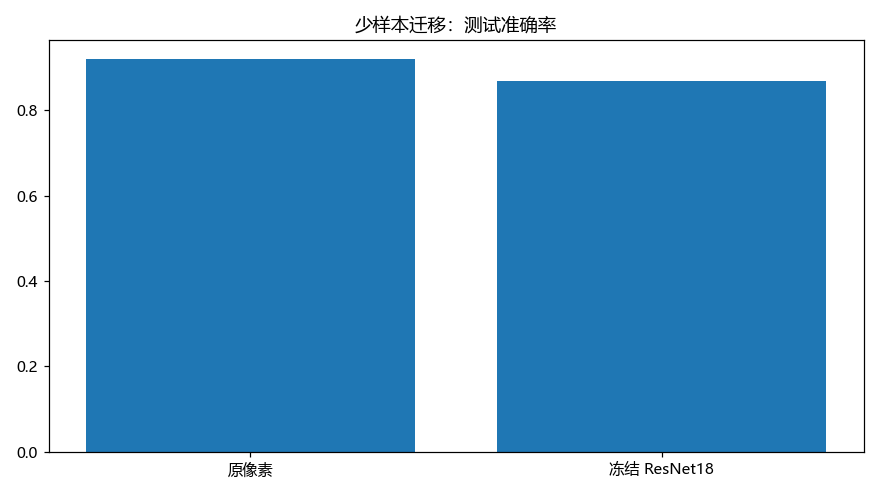

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
ImageNet 与数字领域差异很大；迁移并不必然胜过原像素。完整骨干微调是拓展，必须另留验证集、比较预算。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。